## PCA và trực quan hóa dữ liệu Dry Bean
Thành viên: TV3 – Lam Linh

Notebook thực hiện PCA-01 đến PCA-04: kiểm tra 16 đặc trưng số, chuẩn hóa, giảm xuống hai thành phần, vẽ dữ liệu theo 7 nhãn thật và phân tích kết quả. PCA-05 cung cấp phần nhận nhãn và vẽ kết quả K-Means/DBSCAN do TV6 bàn giao. Khi chưa có nhãn, notebook thông báo chờ dữ liệu và không tạo kết quả gom cụm thay thế.

Đầu vào: CSV do TV2 chuyển từ Excel của nhóm. Giữ nguyên các dòng trùng và ngoại lệ đã ghi nhận ở EDA để thống nhất tập mẫu. Class chỉ dùng để tô màu và mô tả sau PCA, tuyệt đối không nằm trong đầu vào PCA.



## 0. Thiết lập và nguồn dữ liệu
Đường dẫn được tìm từ vị trí notebook. Mã nguồn dữ liệu được cố định tại commit 733587ca92250378bf201f1b3edad6c0b0db00b6 để có thể tái lập kết quả. Nếu đã có CSV ở máy, notebook dùng file đó và ghi lại SHA-256 thực tế. Cơ chế tải chỉ hoạt động khi chưa có file, không ghi đè dữ liệu đang có.

In [4]:
from pathlib import Path
import hashlib
import json
import platform
import urllib.request
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from IPython.display import display, Markdown

REPO_COMMIT = "733587ca92250378bf201f1b3edad6c0b0db00b6"
EXPECTED_CSV_BLOB = "5d73a0b6c225de494ac65f7eaed7fb0aafb71f71"
CSV_URL = (
    "https://raw.githubusercontent.com/tanlen06-debug/Khai_Thac_Du_Lieu_Gr6/"
    f"{REPO_COMMIT}/data/processed/dry_bean.csv"
)
RANDOM_STATE = 42  # Dùng để xáo thứ tự vẽ; PCA full SVD không dùng ngẫu nhiên.

cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents] if (p / "data/processed").is_dir()),
            cwd.parent if cwd.name == "notebooks" else cwd)
DATA_DIR = ROOT / "data/processed"
FIGURES_DIR = ROOT / "outputs/figures"
TABLES_DIR = ROOT / "outputs/tables"
for directory in [DATA_DIR, FIGURES_DIR, TABLES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

csv_path = DATA_DIR / "dry_bean.csv"
if not csv_path.exists():
    print("Chưa có CSV tại máy; đang tải bản cố định từ GitHub của nhóm...")
    with urllib.request.urlopen(CSV_URL, timeout=30) as response:
        downloaded = response.read()
    downloaded_blob = hashlib.sha1(
        b"blob " + str(len(downloaded)).encode() + b"\0" + downloaded
    ).hexdigest()
    if downloaded_blob != EXPECTED_CSV_BLOB:
        raise ValueError("Tệp tải về không khớp bản CSV đã kiểm tra; chưa ghi dữ liệu.")
    csv_path.write_bytes(downloaded)

source_bytes = csv_path.read_bytes()
source_sha256 = hashlib.sha256(source_bytes).hexdigest()
source_blob = hashlib.sha1(
    b"blob " + str(len(source_bytes)).encode() + b"\0" + source_bytes
).hexdigest()
print("Đầu vào:", csv_path.relative_to(ROOT))
print("Khớp bản CSV tham chiếu:", source_blob == EXPECTED_CSV_BLOB)
print("SHA-256:", source_sha256)
print("Python:", platform.python_version(), "| pandas:", pd.__version__,
      "| scikit-learn:", sklearn.__version__)
if source_blob != EXPECTED_CSV_BLOB:
    print("Lưu ý: đang dùng CSV khác bản tham chiếu. Đối chiếu phiên bản với TV2 và TV6.")

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 14, "figure.dpi": 110,
})

Đầu vào: data\processed\dry_bean.csv
Khớp bản CSV tham chiếu: False
SHA-256: 13ab70eb0c36ac3373e21b30135206505d12d10821b00dca4e06acdcf7fb7c18
Python: 3.14.0 | pandas: 3.1.0 | scikit-learn: 1.9.1
Lưu ý: đang dùng CSV khác bản tham chiếu. Đối chiếu phiên bản với TV2 và TV6.


## 05.1. PCA-01 Chuẩn bị đặc trưng và nhãn
Mỗi dòng là một hạt đậu; 16 cột số mô tả hình thái, cột Class là tên giống. Chọn đặc trưng theo ý nghĩa và kiểu số, bao gồm cả Area, ConvexArea dù hai cột này có kiểu số nguyên. Không đưa Class, số thứ tự dòng hay mã kiểm tra vào PCA.

Kiểm tra tên cột, kiểu dữ liệu, giá trị thiếu, vô cùng và lớp trước khi tính. Notebook dừng nếu đầu vào không hợp lệ để người làm xử lý có căn cứ. Với bản hiện tại, giữ nguyên dữ liệu như EDA của TV2; không xóa hàng loạt các điểm vượt IQR.

In [2]:
df = pd.read_csv(csv_path, encoding="utf-8-sig")
FEATURE_COLUMNS = [
    "Area", "Perimeter", "MajorAxisLength", "MinorAxisLength",
    "AspectRation", "Eccentricity", "ConvexArea", "EquivDiameter",
    "Extent", "Solidity", "roundness", "Compactness",
    "ShapeFactor1", "ShapeFactor2", "ShapeFactor3", "ShapeFactor4",
]
EXPECTED_CLASSES = {"BARBUNYA", "BOMBAY", "CALI", "DERMASON", "HOROZ", "SEKER", "SIRA"}
assert df.columns.is_unique, "Có tên cột bị trùng."
assert set(df.columns) == set(FEATURE_COLUMNS + ["Class"]), "Cấu trúc cột không đúng dữ liệu nhóm."

X = df.loc[:, FEATURE_COLUMNS].copy()
y = df["Class"].copy()
assert X.select_dtypes(include="number").shape[1] == 16, "Có đặc trưng chưa ở kiểu số."
assert "Class" not in X.columns and X.shape[1] == 16
assert not df.isna().any().any(), "Có dữ liệu thiếu; cần đối chiếu TV2 trước khi tiếp tục."
assert np.isfinite(X.to_numpy(dtype=float)).all(), "Có giá trị vô cùng trong đặc trưng."
assert set(y.unique()) == EXPECTED_CLASSES, "Nhãn lớp không khớp 7 giống đậu."
assert (X.std(ddof=0) > 0).all(), "Có cột hằng; cần thống nhất cách xử lý."

duplicate_count = int(df.duplicated().sum())
feature_summary = pd.DataFrame({
    "feature": X.columns,
    "dtype": X.dtypes.astype(str).to_numpy(),
    "missing": X.isna().sum().to_numpy(),
    "min": X.min().to_numpy(),
    "max": X.max().to_numpy(),
})
print(f"Dữ liệu: {df.shape[0]:,} dòng × {df.shape[1]} cột")
print(f"X: {X.shape}; y: {y.shape}; số lớp: {y.nunique()}")
print(f"Dòng trùng: {duplicate_count}; chính sách: giữ nguyên để khớp EDA/TV6.")
display(feature_summary)
display(y.value_counts().rename_axis("Class").to_frame("n_samples"))
feature_summary.to_csv(TABLES_DIR / "tv3_feature_summary.csv", index=False, encoding="utf-8-sig")

Dữ liệu: 13,611 dòng × 17 cột
X: (13611, 16); y: (13611,); số lớp: 7
Dòng trùng: 68; chính sách: giữ nguyên để khớp EDA/TV6.


,feature,dtype,missing,min,max
0,Area,int64,0,20420.000000,254616.000000
1,Perimeter,float64,0,524.736000,1985.370000
2,MajorAxisLength,float64,0,183.601165,738.860153
3,MinorAxisLength,float64,0,122.512653,460.198497
4,AspectRation,float64,0,1.024868,2.430306
5,Eccentricity,float64,0,0.218951,0.911423
6,ConvexArea,int64,0,20684.000000,263261.000000
7,EquivDiameter,float64,0,161.243764,569.374358
8,Extent,float64,0,0.555315,0.866195
9,Solidity,float64,0,0.919246,0.994677


,n_samples
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1630
BARBUNYA,1322
BOMBAY,522


## 05.2. PCA-02 Chuẩn hóa và giảm còn hai thành phần
Các đặc trưng có thang đo khác nhau: diện tích có giá trị lớn hơn nhiều chỉ số hình dạng. Chuẩn hóa từng cột giúp phép PCA trên dữ liệu này không chỉ phản ánh sự khác biệt về thang đo.

Với đặc trưng \(j\), StandardScaler thực hiện:

\(z_{ij}=\frac{x_{ij}-\mu_j}{\sigma_j}.\)

PCA tìm các hướng trực giao giữ phương sai lớn. PC1 giữ phương sai lớn nhất; PC2 giữ phương sai lớn tiếp theo trong các hướng vuông góc PC1. Mỗi PC là tổ hợp tuyến tính của 16 đặc trưng đã chuẩn hóa, không phải một cột gốc được chọn ra.


In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

assert np.allclose(X_scaled.mean(axis=0), 0, atol=1e-10)
assert np.allclose(X_scaled.std(axis=0, ddof=0), 1, atol=1e-10)

pca = PCA(n_components=2, svd_solver="full", whiten=False)
X_pca = pca.fit_transform(X_scaled)
explained = pca.explained_variance_ratio_
retained = float(explained.sum())
assert X_pca.shape == (len(df), 2) and np.isfinite(X_pca).all()

variance_table = pd.DataFrame({
    "component": ["PC1", "PC2"],
    "explained_variance_ratio": explained,
    "explained_variance_percent": explained * 100,
    "cumulative_percent": np.cumsum(explained) * 100,
})
display(variance_table.round(6))
print(f"Tổng phương sai giữ lại: {retained:.2%}")
print(f"Phương sai chưa biểu diễn trong 2D: {1-retained:.2%}")
variance_table.to_csv(TABLES_DIR / "tv3_pca_explained_variance.csv", index=False, encoding="utf-8-sig")

# row_id là vị trí dòng gốc; row_hash xác nhận cùng vector đặc trưng, không dùng để fit.
row_ids = np.arange(len(df), dtype=np.int64)
row_hashes = [hashlib.sha256(np.asarray(row, dtype="<f8").tobytes()).hexdigest()
              for row in X.to_numpy(dtype=np.float64)]
pca_df = pd.DataFrame({
    "row_id": row_ids, "row_hash": row_hashes,
    "PC1": X_pca[:, 0], "PC2": X_pca[:, 1], "Class": y.to_numpy(),
})
pca_df.to_csv(TABLES_DIR / "tv3_pca_coordinates.csv", index=False, encoding="utf-8-sig")
display(pca_df.head())

,component,explained_variance_ratio,explained_variance_percent,cumulative_percent
0,PC1,0.554664,55.466439,55.466439
1,PC2,0.264310,26.430973,81.897412


Tổng phương sai giữ lại: 81.90%
Phương sai chưa biểu diễn trong 2D: 18.10%


,row_id,row_hash,PC1,PC2,Class
0,0,56b87ba776031d51a71a98d382ef6932168e13136456a7...,-4.981561,1.824697,SEKER
1,1,d2e95f4e3a9b84deb2da05c94f1db21bda35946063b739...,-5.436792,2.932365,SEKER
2,2,d1a8e4b17e8b062935feef50719d71cdb64930600bd9d5...,-4.758088,1.826884,SEKER
3,3,e099d184eca1837b8bfc43de007d62ddca79c1b6379a90...,-4.300541,2.003661,SEKER
4,4,beae8a6cfa5b9f69c669d76e93c3b512a09dafa269ac77...,-6.349340,4.088205,SEKER


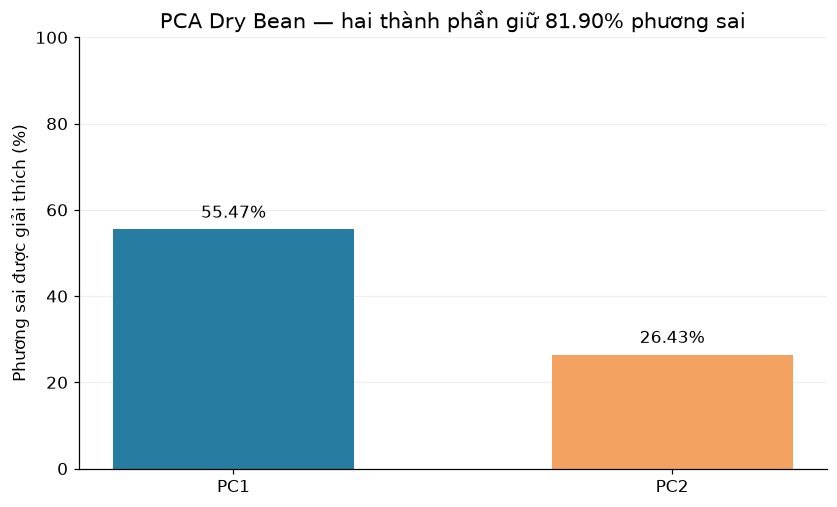

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 4.5), constrained_layout=True)
bars = ax.bar(["PC1", "PC2"], explained * 100, color=["#277DA1", "#F4A261"], width=0.55)
ax.bar_label(bars, labels=[f"{v:.2%}" for v in explained], padding=5)
ax.set_ylim(0, 100)
ax.set_ylabel("Phương sai được giải thích (%)")
ax.set_title(f"PCA Dry Bean — hai thành phần giữ {retained:.2%} phương sai")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
fig.savefig(FIGURES_DIR / "tv3_pca_explained_variance.png", dpi=220, bbox_inches="tight")
plt.show()

## 05.3. PCA-03 Trực quan theo bảy nhãn thật
Vẽ tất cả mẫu ở tọa độ PC1–PC2. Mỗi giống có một màu; chú giải ghi số mẫu của từng lớp. Độ trong suốt giúp quan sát vùng chồng lấn. Thứ tự vẽ được xáo với seed cố định, còn bảng tọa độ bàn giao vẫn giữ thứ tự gốc.

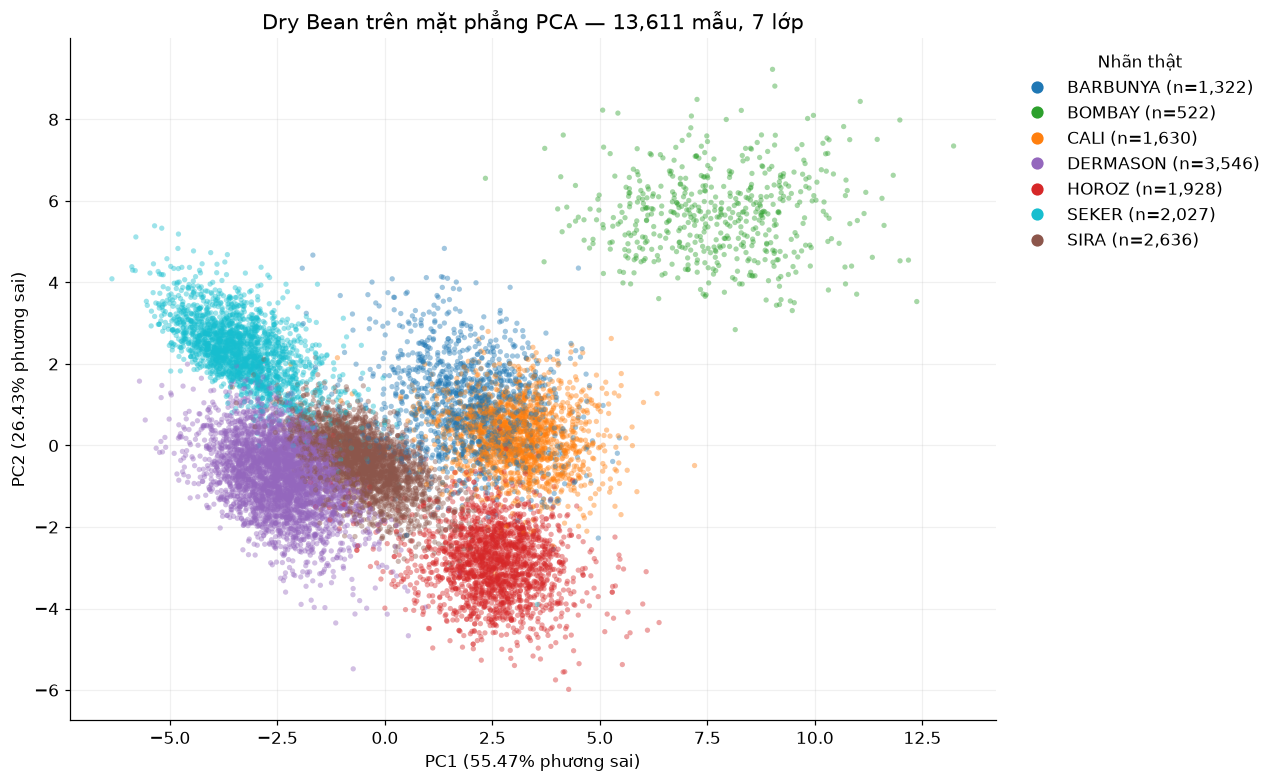

In [7]:
class_order = sorted(y.unique())
colors = ["#1F77B4", "#2CA02C", "#FF7F0E", "#9467BD", "#D62728", "#17BECF", "#8C564B"]
class_colors = dict(zip(class_order, colors))
plot_df = pca_df.sample(frac=1, random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(11.5, 7), constrained_layout=True)
ax.scatter(plot_df["PC1"], plot_df["PC2"],
           c=plot_df["Class"].map(class_colors), s=12, alpha=0.42, linewidths=0, rasterized=True)
handles = [Line2D([0], [0], marker="o", linestyle="", color=class_colors[c],
                  markersize=7, label=f"{c} (n={int((y == c).sum()):,})")
           for c in class_order]
ax.legend(handles=handles, title="Nhãn thật", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.set_xlabel(f"PC1 ({explained[0]:.2%} phương sai)")
ax.set_ylabel(f"PC2 ({explained[1]:.2%} phương sai)")
ax.set_title(f"Dry Bean trên mặt phẳng PCA — {len(df):,} mẫu, 7 lớp")
ax.grid(alpha=0.18)
ax.set_axisbelow(True)
fig.savefig(FIGURES_DIR / "tv3_pca_true_labels.png", dpi=220, bbox_inches="tight")
plt.show()

## 05.4. PCA-04 Phân tích PC1, PC2 và chồng lấn
Đọc hình cùng tỷ lệ phương sai và hệ số của từng PC. Bảng components_ là hệ số tổ hợp tuyến tính; dấu thể hiện hướng biến thiên trên trục. Dấu của một trục PCA có thể đảo giữa các cách cài đặt mà không làm thay đổi cấu trúc phép chiếu. Hệ số lớn theo trị tuyệt đối không đồng nghĩa đặc trưng đó quan trọng nhất cho phân lớp hay có tác động nhân quả.

Bảng tâm lớp và khoảng cách tâm chỉ bổ sung mô tả trên mặt phẳng 2D. Hai tâm gần nhau chưa đủ để chứng minh các phân bố chồng lấn; vẫn phải quan sát độ phân tán của các điểm trên hình.

In [8]:
coefficients = pd.DataFrame(pca.components_.T, index=FEATURE_COLUMNS, columns=["PC1", "PC2"])
coefficients.index.name = "feature"
display(coefficients.round(5))
coefficients.to_csv(TABLES_DIR / "tv3_pca_coefficients.csv", encoding="utf-8-sig")

class_centers = pca_df.groupby("Class")[["PC1", "PC2"]].mean()
pair_distances = pd.DataFrame([
    {"class_a": a, "class_b": b,
     "distance_2d": float(np.linalg.norm(class_centers.loc[a] - class_centers.loc[b]))}
    for a, b in combinations(class_centers.index, 2)
]).sort_values("distance_2d", ignore_index=True)
display(class_centers.round(4))
display(pair_distances.head(3).round(4))

for component in ["PC1", "PC2"]:
    strongest = coefficients[component].abs().nlargest(3).index
    values = ", ".join(f"{f} ({coefficients.loc[f, component]:+.4f})" for f in strongest)
    print(f"Ba hệ số có trị tuyệt đối lớn nhất của {component}: {values}")

display(Markdown(
    f"**Kết quả định lượng:** PC1 giải thích **{explained[0]:.2%}**, "
    f"PC2 giải thích **{explained[1]:.2%}**. Tổng cộng, hai thành phần giữ "
    f"**{retained:.2%} phương sai** của dữ liệu sau chuẩn hóa; còn "
    f"**{1-retained:.2%}** phương sai chưa được thể hiện trên hình 2D. "
    "Tỷ lệ này không phải Accuracy, F1 hoặc tỷ lệ phân loại đúng."
))

,PC1,PC2
feature,,
Area,0.28246,0.24588
Perimeter,0.31089,0.17930
MajorAxisLength,0.32582,0.10076
MinorAxisLength,0.23620,0.34346
AspectRation,0.22930,-0.33084
Eccentricity,0.23153,-0.31943
ConvexArea,0.28320,0.24463
EquivDiameter,0.29748,0.22280
Extent,-0.05981,0.22062


,PC1,PC2
Class,,
BARBUNYA,1.9689,0.9817
BOMBAY,7.7526,5.6548
CALI,3.0779,0.2238
DERMASON,-2.4092,-0.7476
HOROZ,2.5434,-2.8756
SEKER,-3.3055,2.3135
SIRA,-0.5035,-0.4207


,class_a,class_b,distance_2d
0,BARBUNYA,CALI,1.3432
1,DERMASON,SIRA,1.9336
2,BARBUNYA,SIRA,2.8425


Ba hệ số có trị tuyệt đối lớn nhất của PC1: MajorAxisLength (+0.3258), ShapeFactor2 (-0.3146), Perimeter (+0.3109)
Ba hệ số có trị tuyệt đối lớn nhất của PC2: MinorAxisLength (+0.3435), ShapeFactor1 (-0.3325), AspectRation (-0.3308)


**Kết quả định lượng:** PC1 giải thích **55.47%**, PC2 giải thích **26.43%**. Tổng cộng, hai thành phần giữ **81.90% phương sai** của dữ liệu sau chuẩn hóa; còn **18.10%** phương sai chưa được thể hiện trên hình 2D. Tỷ lệ này không phải Accuracy, F1 hoặc tỷ lệ phân loại đúng.

Nhận xét từ hình và giới hạn
Trên bản dữ liệu của nhóm đã kiểm tra, BOMBAY tập trung thành vùng tương đối tách biệt. BARBUNYA và CALI có vùng điểm chồng lấn; DERMASON và SIRA cũng có vùng tiếp giáp, chồng lấn. SEKER và HOROZ có xu hướng nằm ở các vùng riêng hơn trên mặt phẳng, nhưng không thể kết luận tất cả các lớp phân tách hoàn toàn.

PC1 phản ánh một tổ hợp nhiều đặc trưng; các hệ số lớn thể hiện sự tương phản giữa những thuộc tính như MajorAxisLength, Perimeter và ShapeFactor2. PC2 cũng là một tổ hợp, với các hệ số lớn ở MinorAxisLength, ShapeFactor1 và AspectRation. Khi giải thích, đối chiếu dấu và trị số với bảng hệ số thực tế phía trên.

Hai PC giữ phần lớn phương sai sau chuẩn hóa nhưng không bảo toàn toàn bộ thông tin, cũng không tối ưu trực tiếp việc tách 7 lớp. Chồng lấn trong 2D không chứng minh các lớp không phân biệt được trong không gian 16 chiều. Không dùng hình này để suy ra điểm F1 của các mô hình.

Phép chuẩn hóa vẫn nhạy với cực trị; các dòng trùng giữ nguyên có thể ảnh hưởng trọng số của mẫu trong phân bố. Đây là giới hạn cần ghi nhận. Nếu nhóm thay đổi tập dữ liệu hoặc cách xử lý dòng trùng/ngoại lệ, cần chạy lại PCA, xem lại hình và cập nhật nhận xét này.

11–12. PCA-05 Nhận kết quả gom cụm từ TV6
TV3 sử dụng tọa độ PCA làm nền và tô màu bằng nhãn dự đoán từ K-Means/DBSCAN, không tô bằng Class rồi gọi đó là kết quả gom cụm. Nhãn -1 của DBSCAN biểu diễn nhiễu và được vẽ màu xám với dấu x. Mã cụm không tương ứng trực tiếp với tên giống đậu.

Cách bàn giao đề xuất: TV6 cung cấp outputs/tables/tv6_cluster_labels.csv, gồm các cột:
Cột	Ý nghĩa
row_id	Vị trí dòng trong CSV gốc, giữ xuyên suốt xử lý
row_hash	Mã vector đặc trưng, lấy từ bảng tv3_pca_coordinates.csv khi ghép theo row_id
kmeans_label	Nhãn K-Means của chính mẫu đó
dbscan_label	Nhãn DBSCAN của chính mẫu đó, có thể bằng -1


Đây là quy ước đề xuất để tích hợp, chưa phải tệp đã có của TV6. Nếu TV6 xáo thứ tự dòng, vẫn phải giữ đúng row_id của mẫu. Không gán lại 0, 1, 2… sau khi xáo. Nếu TV6 thay đổi tập mẫu (ví dụ loại trùng), hai thành viên cần thống nhất dữ liệu rồi chạy lại phần liên quan. Hàm dưới kiểm tra sự đầy đủ, trùng ID và mã mẫu trước khi vẽ.

In [9]:
def align_cluster_labels(coordinates, labels):
    required = ["row_id", "row_hash", "kmeans_label", "dbscan_label"]
    if not set(required).issubset(labels.columns):
        raise ValueError(f"Tệp TV6 phải có đủ cột: {required}")
    labels = labels.loc[:, required].copy()
    if labels.isna().any().any():
        raise ValueError("Tệp nhãn TV6 có ô thiếu.")
    for column in ["row_id", "kmeans_label", "dbscan_label"]:
        values = pd.to_numeric(labels[column], errors="raise").to_numpy(dtype=float)
        if not np.isfinite(values).all() or not np.equal(values, np.floor(values)).all():
            raise ValueError(f"{column} phải là số nguyên hữu hạn.")
        labels[column] = values.astype(np.int64)
    if labels["row_id"].duplicated().any():
        raise ValueError("row_id bị trùng trong tệp TV6.")
    if len(labels) != len(coordinates) or set(labels["row_id"]) != set(coordinates["row_id"]):
        raise ValueError("Tập mẫu TV6 khác tập PCA. Thống nhất dữ liệu rồi chạy lại, không ghép theo vị trí.")
    if (labels["kmeans_label"] < 0).any() or (labels["dbscan_label"] < -1).any():
        raise ValueError("Nhãn K-Means phải không âm; DBSCAN chỉ dùng -1 cho nhiễu.")
    merged = coordinates.merge(labels, on="row_id", how="left", validate="one_to_one",
                               suffixes=("", "_tv6"), sort=False)
    if not merged["row_hash"].eq(merged["row_hash_tv6"]).all():
        raise ValueError("Mã mẫu không khớp: nhãn và PCA không xuất phát từ cùng dữ liệu/thứ tự ID.")
    return merged.drop(columns="row_hash_tv6")


def plot_cluster_projection(ax, frame, label_column, title, noise_label=None):
    cluster_ids = sorted(c for c in frame[label_column].unique() if c != noise_label)
    cmap = plt.get_cmap("tab20")
    for i, cluster_id in enumerate(cluster_ids):
        subset = frame.loc[frame[label_column] == cluster_id]
        ax.scatter(subset["PC1"], subset["PC2"], s=10, alpha=0.4, linewidths=0,
                   color=cmap(i % 20), label=f"Cụm {cluster_id} (n={len(subset):,})")
    if noise_label is not None:
        noise = frame.loc[frame[label_column] == noise_label]
        if not noise.empty:
            ax.scatter(noise["PC1"], noise["PC2"], s=12, alpha=0.4, c="#555555",
                       marker="x", linewidths=0.5, label=f"Nhiễu -1 (n={len(noise):,})")
    ax.set_title(title)
    ax.set_xlabel(f"PC1 ({explained[0]:.2%})")
    ax.set_ylabel(f"PC2 ({explained[1]:.2%})")
    ax.grid(alpha=0.15)
    ax.set_axisbelow(True)
    # Không giấu cụm nếu có nhiều nhãn: in bảng đếm đầy đủ bên dưới.
    if len(cluster_ids) <= 12:
        ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8, frameon=False)
    else:
        ax.text(0.01, 0.99, "Nhiều cụm; xem bảng đếm nhãn bên dưới.",
                transform=ax.transAxes, va="top", fontsize=9)

In [10]:
cluster_path = TABLES_DIR / "tv6_cluster_labels.csv"
cluster_figures_ready = False
if not cluster_path.exists():
    print("PCA-05: CHỜ NHÃN TV6.")
    print("Đã có hàm nhận nhãn và vẽ. Chưa có kết quả gom cụm thực nghiệm để bàn giao.")
    print("Tệp cần nhận:", cluster_path.relative_to(ROOT))
else:
    supplied_labels = pd.read_csv(cluster_path, encoding="utf-8-sig", dtype={"row_hash": str})
    clustered_df = align_cluster_labels(pca_df, supplied_labels)
    cluster_summary = []
    for column, title, noise_id, filename in [
        ("kmeans_label", "K-Means trên nền PCA 2D", None, "tv3_pca_kmeans.png"),
        ("dbscan_label", "DBSCAN trên nền PCA 2D", -1, "tv3_pca_dbscan.png"),
    ]:
        fig, ax = plt.subplots(figsize=(11.5, 7), constrained_layout=True)
        plot_cluster_projection(ax, clustered_df, column, title, noise_id)
        # Cùng phạm vi trục để đối chiếu hai hình.
        for axis, name in [(ax.set_xlim, "PC1"), (ax.set_ylim, "PC2")]:
            low, high = pca_df[name].min(), pca_df[name].max()
            margin = (high - low) * 0.05
            axis(low - margin, high + margin)
        fig.savefig(FIGURES_DIR / filename, dpi=220, bbox_inches="tight")
        plt.show()
        counts = clustered_df[column].value_counts().sort_index()
        display(counts.rename_axis("label").to_frame("n_samples"))
        noise_count = int((clustered_df[column] == -1).sum()) if noise_id == -1 else 0
        n_clusters = int(clustered_df.loc[clustered_df[column] != -1, column].nunique())
        cluster_summary.append({"algorithm": column, "n_clusters": n_clusters,
                                "n_noise": noise_count, "noise_percent": 100 * noise_count / len(df)})
    display(pd.DataFrame(cluster_summary))
    pd.DataFrame(cluster_summary).to_csv(TABLES_DIR / "tv3_cluster_plot_summary.csv", index=False)
    cluster_figures_ready = True
    print("Đã vẽ nhãn TV6 sau khi kiểm tra khớp mẫu. Bổ sung nhận xét thực nghiệm của hai hình.")

PCA-05: CHỜ NHÃN TV6.
Đã có hàm nhận nhãn và vẽ. Chưa có kết quả gom cụm thực nghiệm để bàn giao.
Tệp cần nhận: outputs\tables\tv6_cluster_labels.csv


Cách hoàn thiện nhận xét PCA-05 khi có nhãn
Đối chiếu từng hình dự đoán với hình 7 nhãn thật: cụm nào bao phủ nhiều vùng lớp, vùng nào bị tách thành nhiều cụm, điểm nhiễu DBSCAN tập trung ở đâu. Báo số cụm và số/tỷ lệ nhiễu từ bảng đếm. Trường hợp tất cả là nhiễu hoặc chỉ một cụm vẫn phải báo đúng kết quả. Phối hợp TV6 để đọc bảng ARI; không tự gán tên giống cho mã cụm, không suy ra ARI từ màu sắc.

Code nhận nhãn chạy được chưa đồng nghĩa nhiệm vụ PCA-05 đã hoàn thành: vẫn cần nhãn thật do thuật toán chạy, hai hình tương ứng và nhận xét từ kết quả đó.

Bàn giao và kiểm tra kết quả
Các tệp có tiền tố tv3_ là sản phẩm của notebook này, giúp tránh ghi đè kết quả EDA của thành viên khác. Nhật ký ghi phiên bản thư viện, chính sách dữ liệu và tham số thực nghiệm. Bảng trạng thái dưới đây phản ánh kết quả chạy trong notebook, không thay thế việc nhóm trưởng duyệt trên bảng tiến độ.

In [11]:
metadata = {
    "source_url": CSV_URL, "reference_commit": REPO_COMMIT,
    "actual_csv_sha256": source_sha256, "actual_csv_git_blob": source_blob,
    "rows": len(df), "features": FEATURE_COLUMNS, "classes": class_order,
    "duplicate_rows_retained": duplicate_count, "data_policy": "keep_all_rows_as_TV2_EDA",
    "scaler": "StandardScaler(with_mean=True, with_std=True)",
    "pca": {"n_components": 2, "svd_solver": "full", "whiten": False},
    "plot_random_state": RANDOM_STATE,
    "explained_variance_ratio": explained.tolist(),
    "versions": {"python": platform.python_version(), "numpy": np.__version__,
                 "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
                 "matplotlib": matplotlib.__version__},
    "cluster_figures_generated": cluster_figures_ready,
}
(TABLES_DIR / "tv3_pca_run_metadata.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8"
)
status = pd.DataFrame({
    "task": ["PCA-01", "PCA-02", "PCA-03", "PCA-04", "PCA-05"],
    "evidence": ["X/y và kiểm tra dữ liệu", "Bảng phương sai PC1/PC2", "Hình 7 lớp",
                 "Bảng hệ số và phân tích PCA",
                 "Hai hình từ nhãn TV6" if cluster_figures_ready else "Hàm đã sẵn sàng, chờ nhãn TV6"],
    "review": ["Chờ người thực hiện rà soát và NT duyệt"] * 4 +
              ["Cần viết nhận xét và NT duyệt" if cluster_figures_ready else "Chưa hoàn thành"],
})
display(status)
print("Bảng/hình của TV3 trong lần chạy này:")
for folder in [TABLES_DIR, FIGURES_DIR]:
    for path in sorted(folder.glob("tv3_*")):
        print("-", path.relative_to(ROOT))

,task,evidence,review
0,PCA-01,X/y và kiểm tra dữ liệu,Chờ người thực hiện rà soát và NT duyệt
1,PCA-02,Bảng phương sai PC1/PC2,Chờ người thực hiện rà soát và NT duyệt
2,PCA-03,Hình 7 lớp,Chờ người thực hiện rà soát và NT duyệt
3,PCA-04,Bảng hệ số và phân tích PCA,Chờ người thực hiện rà soát và NT duyệt
4,PCA-05,"Hàm đã sẵn sàng, chờ nhãn TV6",Chưa hoàn thành


Bảng/hình của TV3 trong lần chạy này:
- outputs\tables\tv3_feature_summary.csv
- outputs\tables\tv3_pca_coefficients.csv
- outputs\tables\tv3_pca_coordinates.csv
- outputs\tables\tv3_pca_explained_variance.csv
- outputs\tables\tv3_pca_run_metadata.json
- outputs\figures\tv3_pca_explained_variance.png
- outputs\figures\tv3_pca_true_labels.png


## Bàn giao và kiểm tra

- [ ] Có giải thích thuật toán/kiến thức từng phần.
- [ ] Code chạy được từ đầu đến cuối (Restart & Run All).
- [ ] Không có số liệu hoặc điểm đánh giá được ghi cứng.
- [ ] Có bảng/biểu đồ và nhận xét từ kết quả thật.
- [ ] Đã push lên nhánh cá nhân và tạo Pull Request để trưởng nhóm xem xét (khi nhóm bắt đầu làm).
